# **Población en Chile y Sistema de Salud. Periodo 2010 - 2024 (sin proyección)**


<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

# 💾 **Setup**
<br>








  ## Cargar información



In [13]:
# Importar liberías

  ## Manejo de base y estadísticas
import pandas as pd
import numpy as np

  ## Gráficas

import plotly.graph_objects as go
from plotly.io import show

# Ruta
path_dw='../1 Data multidimensional/'


In [55]:
# Dimensiones

  ## Edad
edad = pd.read_parquet(path_dw + 'DIM_EDAD.parquet')

  ## Población
pob = pd.read_parquet(path_dw + 'DW_POBLACION_COMUNAS.parquet')

  ## Comunas
comuna = pd.read_parquet(path_dw + 'DIM_COMUNAS.parquet')

  ## Registros afiliación a Sistema de salud
df=pd.read_parquet(path_dw + 'FACT_BENEFICIARIOS_COMUNAS.parquet')


<br>

## Modificar bases

In [58]:
# Ajuste población

  ## Cruce y agrupación
pob=(pob[['Sexo','Edad','Comuna','Año','Poblacion']].merge(edad[['Edad','RangoEdad10']], on='Edad', how='left')).groupby(['Año','Comuna','Sexo','RangoEdad10'])['Poblacion'].sum().reset_index()
pob=pob.merge(comuna[['Comuna','Region']], on='Comuna', how='left')
pob=pob[['Año','Region','Comuna','Sexo','RangoEdad10','Poblacion']]

  ## Creación de bases población relevantes para posterior uso
pob_comuna=pob[pob['Año']<2025].groupby(['Año','Comuna'])['Poblacion'].sum().reset_index()
pob_region=pob[pob['Año']<2025].groupby(['Año','Region'])['Poblacion'].sum().reset_index()
pob_nacional=pob[pob['Año']<2025].groupby(['Año'])['Poblacion'].sum().reset_index()



In [59]:
# Ajuste comunas

## Modificación nombre de comunas
diccionario_region={
    "Libertador General Bernardo O'Higgins": "O'Higgins",
    'Aysén del General Carlos Ibáñez del Campo': 'Aysén',
    'Magallanes y de la Antártica Chilena': 'Magallanes',
    'Metropolitana de Santiago': 'Metropolitana'}


comuna['Nombre Region'] = comuna['Nombre Region'].map(diccionario_region).fillna(comuna['Nombre Region'])

In [62]:
# Ajuste base general

  ## Incorporación de comuna y region

df= (df.rename(columns={'Comuna2024':'Comuna'}).fillna(value={'Comuna':99}).
     merge(comuna[['Comuna','Region']], on='Comuna', how='left').astype({'Region':'Int64'}))

  ## Beneficiarios NA a 0
df['Beneficiarios']=df['Beneficiarios'].fillna(0).astype('Int64')

  ## Rescribir Tramo
diccionario_tramos = {
    'A': 'Tramo A',
    'B': 'Tramo B',
    'C': 'Tramo C',
    'D': 'Tramo D',
    'I': 'Isapre'}

df["Tramo"] = df["Tramo"].map(diccionario_tramos).fillna(df["Tramo"])

<br>
<br>
...............................................................................................................................................................................................................................................
<br>
<br>

# **Caracterización de datos perdidos**

## Ajustar bases

In [66]:
# Ajuste base general

  ## Simplificación: Reemplazo de datos perdidos por 99
df.loc[df['Region'].isna(), 'Region'] = 99
df.loc[df['Comuna'].isna(), 'Comuna'] = 99
df.loc[df['Sexo'].isin([3, 99]), 'Sexo'] = 99
df.loc[df['RangoEdad10'].isna(), 'RangoEdad10'] = 99

df=df.groupby(['Año','Region','Comuna','Tramo','Sexo','RangoEdad10'])['Beneficiarios'].sum(min_count=1).reset_index()

  ## Identificación data perdida
df['Missing'] = 'Válida'
df.loc[((df.Region==99) | (df.Comuna==99) | df.Sexo.isin([3,99]) | (df.RangoEdad10==99)), 'Missing'] = 'Perdida'


  ## Identificación tipo data perdida
df['Tipo Error']='Data válida'
df.loc[df['Comuna']==99, 'Tipo Error'] = 'Data perdida: Data sin comuna'
df.loc[((df['Comuna']!=99) & ((df['Sexo']==99) | (df['RangoEdad10']==99))), 'Tipo Error'] = 'Data perdida: Comuna con data perdida'

<br>

## Visualización periodo completo

### Gráfica data perdida por año

In [70]:
# Transformación de base para gráfico

df = df[df['Año']>=2010].copy()

  ## Primer nivel
df_graf = df.pivot_table(index=['Año', 'Missing'], columns='Tramo', values='Beneficiarios', aggfunc='sum').fillna(0).reset_index()


  ## Segundo Nivel
tramos = ['Isapre', 'Tramo A', 'Tramo B', 'Tramo C', 'Tramo D']
df_graf = df_graf.melt(id_vars=['Año', 'Missing'], value_vars=tramos, var_name='Tramo_agrup', value_name='Beneficiarios')
df_graf = df_graf.pivot_table(index='Año', columns=['Missing', 'Tramo_agrup'], values='Beneficiarios', aggfunc='sum').fillna(0)


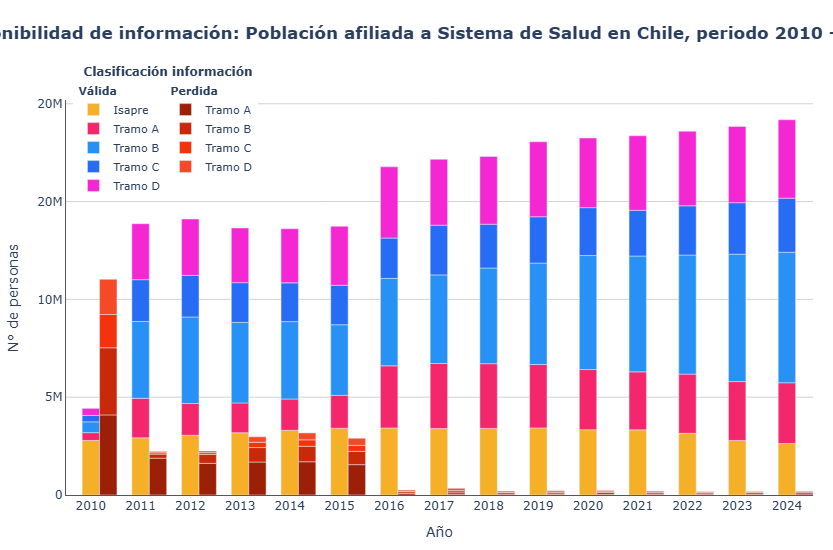

In [72]:


# Gráfico

  ## Colores y definiciones
colores = {
    "Válida":{
    "Tramo A": "#F5276C",
    "Tramo B": "#2791F5",
    "Tramo C": "#276CF5",
    "Tramo D": "#F527D3",
    "Isapre": "#F5B027"},
    "Perdida":{
    'Isapre':  '#701705',
    'Tramo A': '#9C2007',
    'Tramo B': '#C82909',
    'Tramo C': '#F4320B',
    'Tramo D': '#F54927'}}

numero_grupos = len(colores)
ancho_barra = 0.35


fig = go.Figure(
    layout=go.Layout(
        barmode="relative",
        bargap=0.30,

  ## Coordinación con segunda capa
        yaxis2=go.layout.YAxis(
            visible=False,
            matches="y",
            overlaying="y",
            anchor="x")))

  ## Creación de barras
for i, j in enumerate(colores):
    for col in df_graf[j].columns:
        if (df_graf[j][col] == 0).all():
            continue
        fig.add_bar(
            x=df_graf.index,
            y=df_graf[(j,col)],
            yaxis=f"y{i + 1}",
            offsetgroup=str(i),
            offset=(i - (numero_grupos - 1) / 2) * ancho_barra,
            width=ancho_barra,
            legendgroup=j,
            legendgrouptitle=dict(
                text=j,
                font=dict(size=11,
                          weight="bold")),
            name=col,
            marker_color=colores[j][col],
            hovertemplate="Año: %{x}<br>Valor: %{y}<extra></extra>")

  ## Ejes y Layout
fig.update_xaxes(title_text='Año', tickmode='linear', dtick=1, showline=True, linecolor='#575757',linewidth=1)
fig.update_yaxes(title_text='N° de personas', tickformat=',.0s', showline=True, linecolor='#575757',linewidth=1,showgrid=True,gridcolor='lightgray', showticklabels=True)



fig.update_layout(title_text='<b> Disponibilidad de información: Población afiliada a Sistema de Salud en Chile, periodo 2010 - 2024</b>',title_x=0.5,title_y=0.95, height=550, width=1200,
                  legend=dict(
                      title=dict(text='<b> Clasificación información', side="top center", font=dict(size=12)),
                      orientation="h",
                      y=1.1,
                      x=0.01,
                      font=dict(size=11)),
                  margin=dict(b=20,t=100,l=30,r=20),
                  plot_bgcolor='white')




fig.show()

<br>
<br>

### Tabla % data perdida por año

In [75]:
# Creación de base

  ## Agrupación por año
df_tabla_año=df.groupby(['Año','Missing'])['Beneficiarios'].sum().reset_index()
df_tabla_año=df_tabla_año.pivot(index='Año', columns='Missing', values='Beneficiarios').fillna(0)
df_tabla_año['Total']=df_tabla_año['Perdida']+df_tabla_año['Válida']

  ## Cálculo de porcentajes
df_tabla_año['Data perdida']=round(df_tabla_año['Perdida']/df_tabla_año['Total']*100,2)
df_tabla_año['Data válida']=round(df_tabla_año['Válida']/df_tabla_año['Total']*100,2)
df_tabla_año.reset_index(inplace=True)

  ## Ajustar base
df_tabla_año=df_tabla_año.melt(id_vars='Año',value_vars=['Data perdida', 'Data válida'],
    var_name='%',value_name='Valores')
df_tabla_año=df_tabla_año.pivot(index='%', columns='Año', values='Valores').reset_index()
df_tabla_año

Año,%,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Data perdida,71.35,13.84,13.75,17.89,18.91,17.44,1.5,1.95,1.17,1.18,1.25,1.07,0.9,0.93,1.02
1,Data válida,28.65,86.16,86.25,82.11,81.09,82.56,98.5,98.05,98.83,98.82,98.75,98.93,99.1,99.07,98.98


### Tabla % data perdida por año y tramo

In [78]:
# Creación de base

  ## Agrupación por año y tramo
df_tabla_tramo_año=df.groupby(['Año','Tramo','Missing'])['Beneficiarios'].sum().reset_index()
df_tabla_tramo_año=df_tabla_tramo_año.pivot(index=['Año','Tramo'], columns='Missing', values='Beneficiarios').fillna(0)
df_tabla_tramo_año['Total']=df_tabla_tramo_año['Perdida']+df_tabla_tramo_año['Válida']

  ## Cálculo de porcentajes
df_tabla_tramo_año['% Data perdida']=round(df_tabla_tramo_año['Perdida']/df_tabla_tramo_año['Total']*100,2)
df_tabla_tramo_año['% Data válida']=round(df_tabla_tramo_año['Válida']/df_tabla_tramo_año['Total']*100,2)

  ## Ajustar base
df_tabla_tramo_año.reset_index(inplace=True)
df_tabla_tramo_año=df_tabla_tramo_año.pivot(index='Tramo', columns='Año', values='% Data perdida').reset_index()
df_tabla_tramo_año

Año,Tramo,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,Isapre,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,Tramo A,91.13,48.24,49.9,52.49,51.5,47.97,2.61,1.34,1.18,0.94,1.09,1.11,1.09,1.05,1.6
2,Tramo B,86.11,5.05,9.35,15.25,16.67,15.84,1.84,2.29,1.65,1.51,1.56,1.34,1.15,1.27,1.32
3,Tramo C,83.9,3.2,4.11,11.65,14.26,13.15,1.48,3.2,1.37,1.6,1.66,1.33,1.01,0.88,0.86
4,Tramo D,83.28,2.32,2.79,9.16,11.31,10.8,1.49,3.06,1.51,1.71,1.76,1.38,1.04,0.94,0.85


<br>
<br>

## Detalle data perdida por año


In [83]:
# Crear base

  ## Filtro periodo
df=df[df['Año']>2009]

  ## Data perdida por tipo de dato
df_miss_dato=df.groupby(['Año','Tipo Error'])['Beneficiarios'].sum().reset_index()
df_miss_dato=df_miss_dato.pivot(index='Año', columns='Tipo Error', values='Beneficiarios').fillna(0)
df_miss_dato['Total']=df_miss_dato['Data perdida: Data sin comuna']+df_miss_dato['Data perdida: Comuna con data perdida']+df_miss_dato['Data válida']
df_miss_dato['% Data perdida: Data sin comuna']=round(df_miss_dato['Data perdida: Data sin comuna']/df_miss_dato['Total']*100,2)
df_miss_dato['% Data perdida: Comuna con data perdida']=round(df_miss_dato['Data perdida: Comuna con data perdida']/df_miss_dato['Total']*100,2)
df_miss_dato['% Data válida']=round(df_miss_dato['Data válida']/df_miss_dato['Total']*100,2)
df_miss_dato=df_miss_dato.reset_index()


  ## Reordenar
df_miss_dato = df_miss_dato.melt(id_vars='Año',value_vars=['% Data perdida: Data sin comuna', '% Data perdida: Comuna con data perdida', '% Data válida'],
    var_name='Tipo Error',value_name='%')

## Tabla data perdida detalle
df_miss_dato = df_miss_dato.pivot(index='Tipo Error', columns='Año', values='%').reset_index()

orden_tipo_error = ['% Data válida', '% Data perdida: Data sin comuna', '% Data perdida: Comuna con data perdida']
df_miss_dato = df_miss_dato.set_index('Tipo Error').loc[orden_tipo_error].reset_index()
df_miss_dato = df_miss_dato.rename(columns={'Tipo Error': ''})


print("Data perdida, clasificación general")
df_miss_dato

Data perdida, clasificación general


Año,,2010,2011,2012,2013,2014,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024
0,% Data válida,28.65,86.16,86.25,82.11,81.09,82.56,98.5,98.05,98.83,98.82,98.75,98.93,99.1,99.07,98.98
1,% Data perdida: Data sin comuna,71.35,13.84,13.74,17.89,18.9,17.43,1.48,0.86,1.16,1.16,1.23,1.05,0.88,0.9,1.0
2,% Data perdida: Comuna con data perdida,0.0,0.01,0.01,0.01,0.01,0.01,0.02,1.09,0.01,0.02,0.02,0.02,0.02,0.02,0.03
